### Imports and Preprocessing

In [ ]:
pip install umap-learn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.cross_decomposition import CCA
from umap import UMAP
from sklearn.metrics import f1_score

In [ ]:
X = pd.read_csv('/content/drive/MyDrive/LINCS/replicate_level_cp_augmented.csv')

<ipython-input-4-1f9f2c7f287f>:1: DtypeWarning: Columns (18,19,1820,1821) have mixed types. Specify dtype option on import or set low_memory=False.
  X = pd.read_csv('/content/drive/MyDrive/LINCS/replicate_level_cp_augmented.csv')


In [ ]:
drop_list = []
for i in range(26,1809):
  if(X[X.columns[i]].isna().sum()!=0):
    drop_list.append(X.columns[i])

In [ ]:
X = X.drop(drop_list, axis=1)

In [ ]:
X

,Metadata_plate_map_name,Metadata_broad_sample,Metadata_mg_per_ml,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,Metadata_pert_mfc_id,Metadata_pert_well,Metadata_pert_id_vendor,Metadata_cell_id,...,moa,target,broad_date,clinical_phase,alternative_moa,alternative_target,Metadata_dose_recode,Metadata_pert_id_dose,pert_type,control_type
0,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A01,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
1,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A02,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
2,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A03,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
3,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A04,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
4,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A05,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52218,C-7161-01-LM6-015,BRD-K61567297-001-01-9,1.206100,3.333300,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P20,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,3.33,BRD-K61567297_3.33,trt,NaN
52219,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.402020,1.111100,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P21,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,1.11,BRD-K61567297_1.11,trt,NaN
52220,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.134010,0.370370,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P22,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,0.37,BRD-K61567297_0.37,trt,NaN
52221,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.044669,0.123460,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P23,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,0.12,BRD-K61567297_0.12,trt,NaN


In [ ]:
X.columns[-20:]

Index(['Nuclei_Texture_Variance_RNA_10_0', 'Nuclei_Texture_Variance_RNA_20_0',
       'Nuclei_Texture_Variance_RNA_5_0', 'broad_id', 'plate_map_name',
       'solvent', 'Batch_Number', 'Batch_Date', 'pert_iname', 'InChIKey14',
       'moa', 'target', 'broad_date', 'clinical_phase', 'alternative_moa',
       'alternative_target', 'Metadata_dose_recode', 'Metadata_pert_id_dose',
       'pert_type', 'control_type'],
      dtype='object')

In [ ]:
X.columns[:30]

Index(['Metadata_plate_map_name', 'Metadata_broad_sample',
       'Metadata_mg_per_ml', 'Metadata_mmoles_per_liter', 'Metadata_solvent',
       'Metadata_pert_id', 'Metadata_pert_mfc_id', 'Metadata_pert_well',
       'Metadata_pert_id_vendor', 'Metadata_cell_id',
       'Metadata_broad_sample_type', 'Metadata_pert_vehicle',
       'Metadata_pert_type', 'Metadata_broad_id', 'Metadata_InChIKey14',
       'Metadata_moa', 'Metadata_target', 'Metadata_broad_date',
       'Metadata_alternative_moa', 'Metadata_alternative_target',
       'Metadata_Plate', 'Metadata_Well', 'Metadata_Assay_Plate_Barcode',
       'Metadata_Plate_Map_Name', 'Metadata_Batch_Number',
       'Metadata_Batch_Date', 'Cells_AreaShape_Area',
       'Cells_AreaShape_Center_X', 'Cells_AreaShape_Center_Y',
       'Cells_AreaShape_Compactness'],
      dtype='object')

### Projection Pursuit

In [ ]:
X.groupby('Metadata_Batch_Date', group_keys=False).apply(lambda x: x.sample(frac=0.5)).to_csv('/content/drive/MyDrive/LINCS/X_samp.csv')

In [ ]:
X_sample = pd.read_csv('/content/drive/MyDrive/LINCS/X_sample_LINCS.csv')

In [ ]:
X_samp = pd.read_csv('/content/drive/MyDrive/LINCS/X_samp_LINCS.csv')

In [ ]:
X_samp['Projection 1.2'] = X_sample['Projection 1.2']
X_samp['Projection 2.2'] = X_sample['Projection 2.2']
X_samp['Projection 1.1'] = X_sample['Projection 1.1']
X_samp['Projection 2.1'] = X_sample['Projection 2.1']
X_samp['Projection 1'] = X_sample['Projection 1']
X_samp['Projection 2'] = X_sample['Projection 2']

In [ ]:
holes_df = X_samp[['Projection 1.2','Projection 2.2']]

In [ ]:
X_samp

,Unnamed: 0,Metadata_plate_map_name,Metadata_broad_sample,Metadata_mg_per_ml,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,Metadata_pert_mfc_id,Metadata_pert_well,Metadata_pert_id_vendor,...,Metadata_dose_recode,Metadata_pert_id_dose,pert_type,control_type,Projection 1.2,Projection 2.2,Projection 1.1,Projection 2.1,Projection 1,Projection 2
0,46656,C-7161-01-LM6-028,BRD-K94830329-001-03-0,0.947470,3.33330,DMSO,BRD-K94830329,BRD-K94830329-001-03-0,I02,NaN,...,3.33,BRD-K94830329_3.33,trt,NaN,-0.264300,0.828448,0.288212,-1.114799,0.227722,0.593559
1,23331,C-7161-01-LM6-011,BRD-K07208025-001-29-7,0.035842,0.12346,DMSO,BRD-K07208025,BRD-K07208025-001-29-7,M05,NaN,...,0.12,BRD-K07208025_0.12,trt,NaN,-0.354366,0.549778,0.508580,-0.268230,0.425633,-0.097072
2,36996,C-7161-01-LM6-003,BRD-K32501161-300-06-2,1.744900,3.33330,DMSO,BRD-K32501161,BRD-K32501161-300-06-2,F14,NaN,...,3.33,BRD-K32501161_3.33,trt,NaN,0.766443,-1.314715,-0.243819,-0.164443,-0.242546,0.459553
3,21140,C-7161-01-LM6-020,BRD-K83405785-001-01-5,0.158350,0.37037,DMSO,BRD-K83405785,BRD-K83405785-001-01-5,A22,NaN,...,0.37,BRD-K83405785_0.37,trt,NaN,0.049608,0.972040,-0.790965,-0.343060,0.014284,-0.317811
4,2056,C-7161-01-LM6-024,BRD-K75089421-003-24-5,0.033554,0.12346,DMSO,BRD-K75089421,BRD-K75089421-003-24-5,F17,NaN,...,0.12,BRD-K75089421_0.12,trt,NaN,0.637130,-1.249294,-0.939088,-0.219807,-0.521202,-0.115706
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26107,41855,C-7161-01-LM6-016,DMSO,0.000000,0.00000,DMSO,NaN,NaN,A01,NaN,...,0.04,negcon,control,negcon,-0.616425,-0.256700,0.960796,-0.433638,0.816185,-1.062279
26108,41798,C-7161-01-LM6-016,BRD-K07572174-001-17-0,0.136440,0.37037,DMSO,BRD-K07572174,BRD-K07572174-001-17-0,N16,NaN,...,0.37,BRD-K07572174_0.37,trt,NaN,-0.839716,1.429926,-0.855078,-0.736220,0.549309,0.243597
26109,42155,C-7161-01-LM6-016,BRD-K36324071-363-01-3,15.132000,10.00000,DMSO,BRD-K36324071,BRD-K36324071-363-01-3,M13,NaN,...,10.00,BRD-K36324071_10.0,trt,NaN,0.950355,0.243378,-2.045890,0.352449,-0.555066,-0.791867
26110,16542,C-7161-01-LM6-021,BRD-K80267133-001-17-7,0.510450,3.33330,DMSO,BRD-K80267133,BRD-K80267133-001-17-7,B08,NaN,...,3.33,BRD-K80267133_3.33,trt,NaN,0.254409,0.173832,-0.904599,0.241364,0.100652,-0.080164


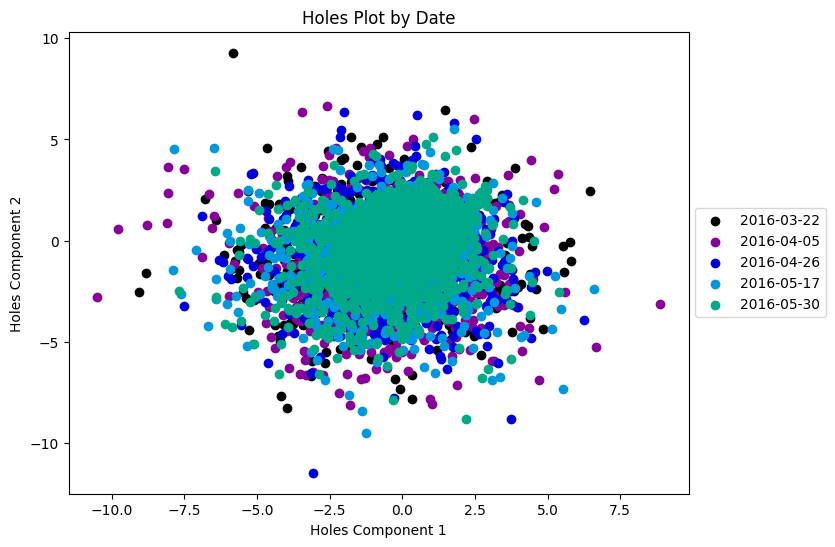

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Holes Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X_samp['Metadata_Batch_Date'].unique():
  plt.scatter(X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 1.2'], X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 2.2'], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Holes Component 1')
plt.ylabel('Holes Component 2')
plt.show()

In [ ]:
hermite_df = X_samp[['Projection 1.1','Projection 2.1']]

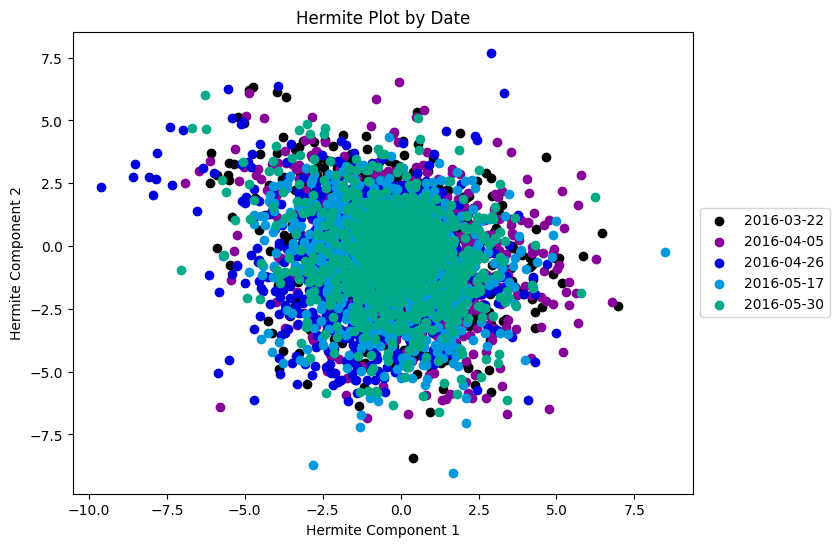

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Hermite Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X_samp['Metadata_Batch_Date'].unique():
  plt.scatter(X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 1'], X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 2'], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Hermite Component 1')
plt.ylabel('Hermite Component 2')
plt.show()

In [ ]:
naturalhermite_df = X_samp[['Projection 1.2','Projection 2.2']]

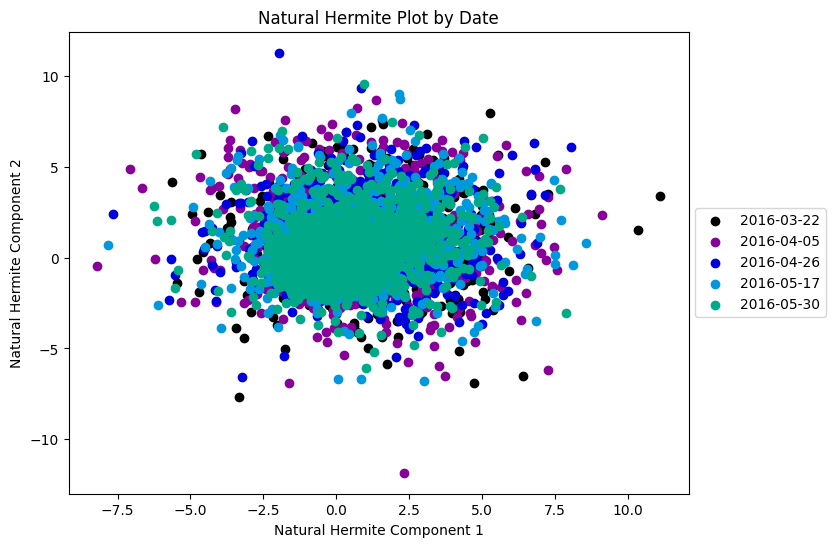

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Natural Hermite Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X_samp['Metadata_Batch_Date'].unique():
  plt.scatter(X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 1.1'], X_samp[X_samp['Metadata_Batch_Date']==i]['Projection 2.1'], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Natural Hermite Component 1')
plt.ylabel('Natural Hermite Component 2')
plt.show()

### Modeling

In [ ]:
# Get list of column names
columns = X.columns.tolist()
# Choose a random column
random_column = random.choice(columns)

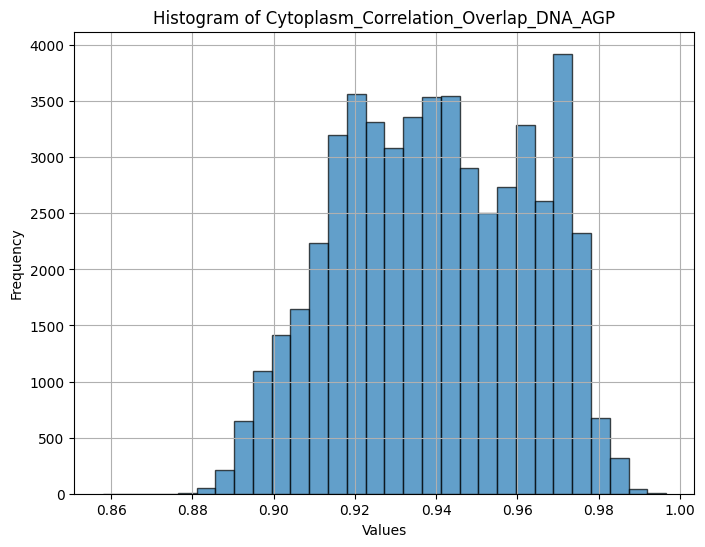

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(X[random_column], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title(f'Histogram of {random_column}')
plt.grid(True)
plt.show()

In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X[X.columns[26:-17]])

In [ ]:
pca = PCA(n_components=2)  # Specify the number of principal components to keep
X_pca = pca.fit_transform(Xs)

In [ ]:
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
X_tsne_10 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42)
X_tsne_30 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42, perplexity=50)
X_tsne_50 = tsne.fit_transform(Xs)

In [ ]:
umap = UMAP(n_components=2, n_neighbors = 10)
X_umap_10 = umap.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 30)
X_umap_30 = umap.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50 = umap.fit_transform(Xs)

In [ ]:
X_tsne = pd.read_csv('/content/drive/MyDrive/LINCS/X_tsne.csv')

In [ ]:
X_tsne = X_tsne.drop('Unnamed: 0', axis = 1).values

In [ ]:
df = X_tsne_10

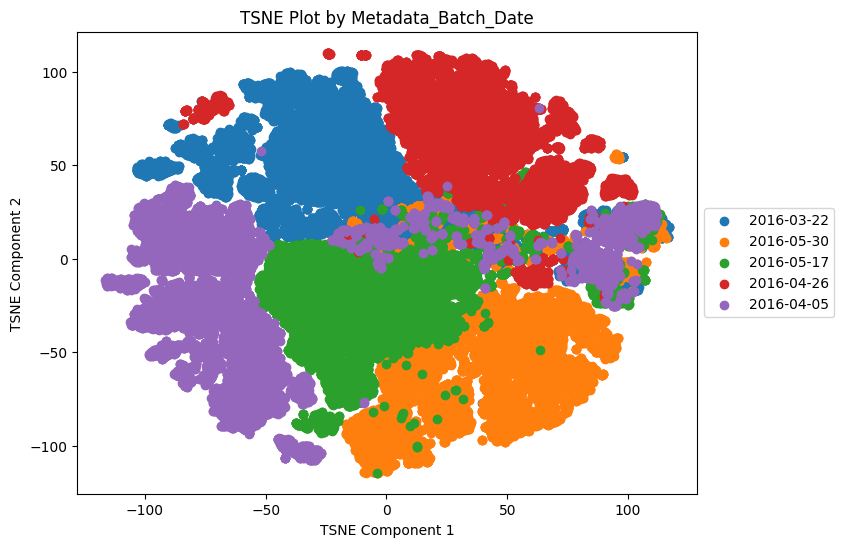

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_30

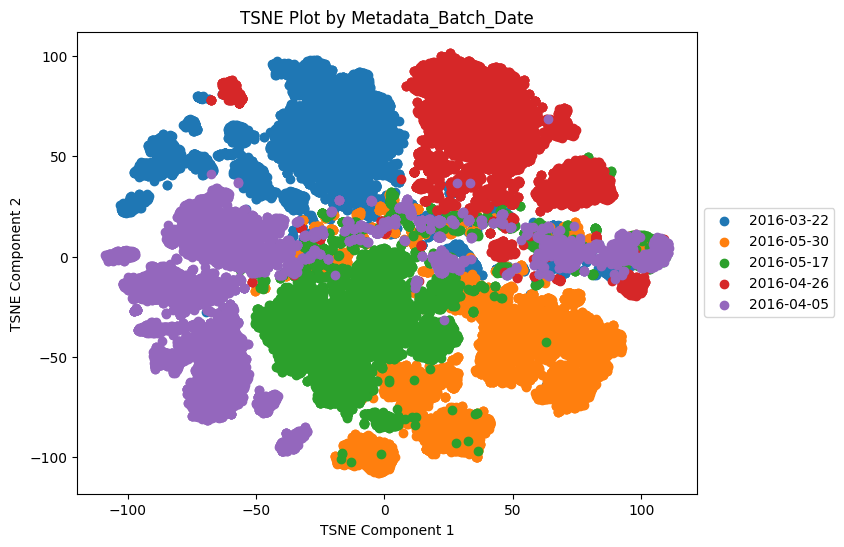

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_50

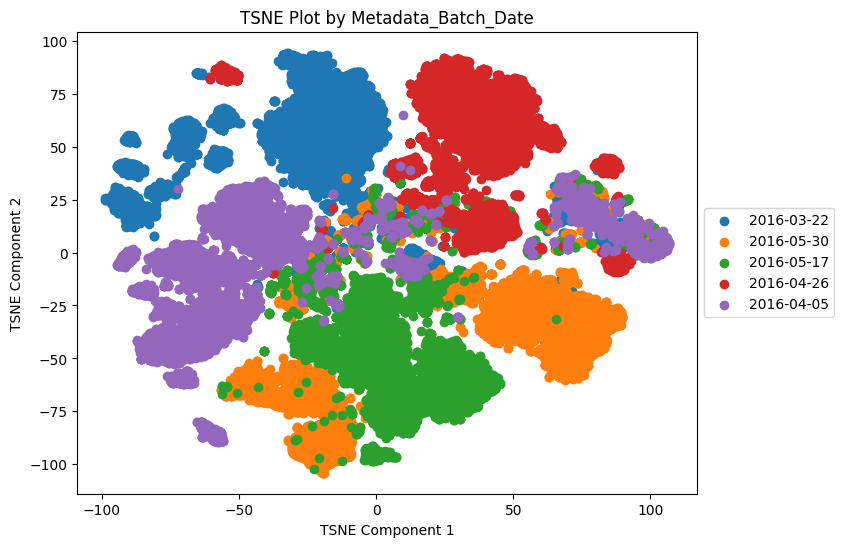

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_pca

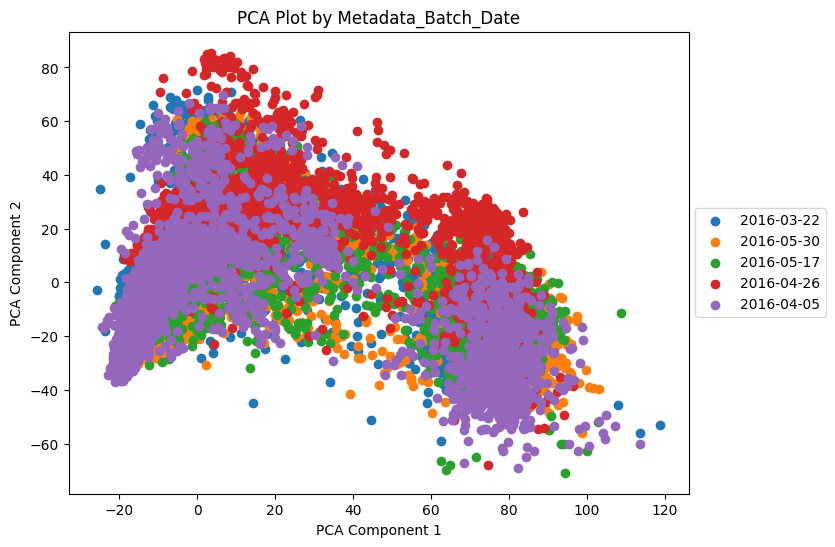

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('PCA Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [ ]:
df= X_umap_10

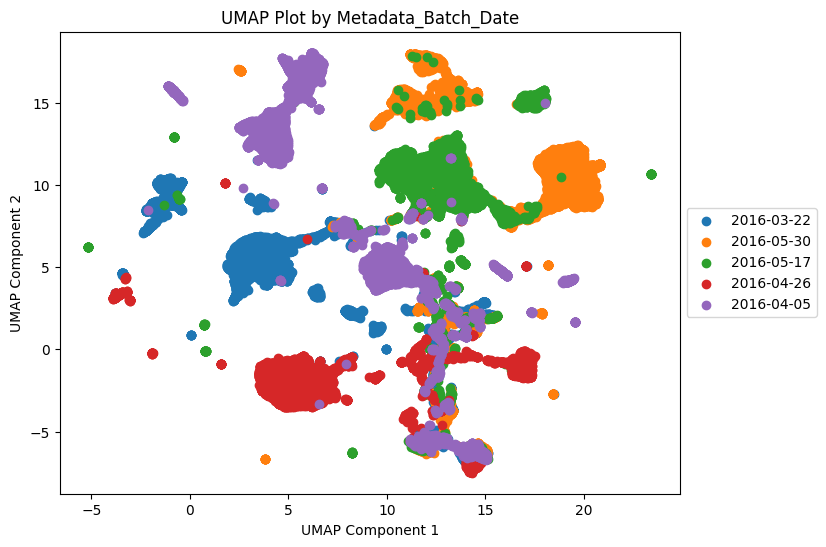

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_30

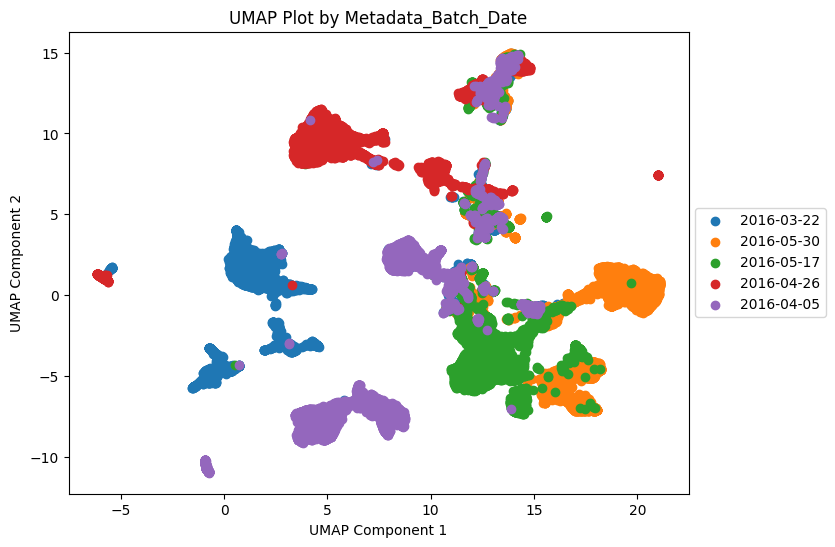

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_50

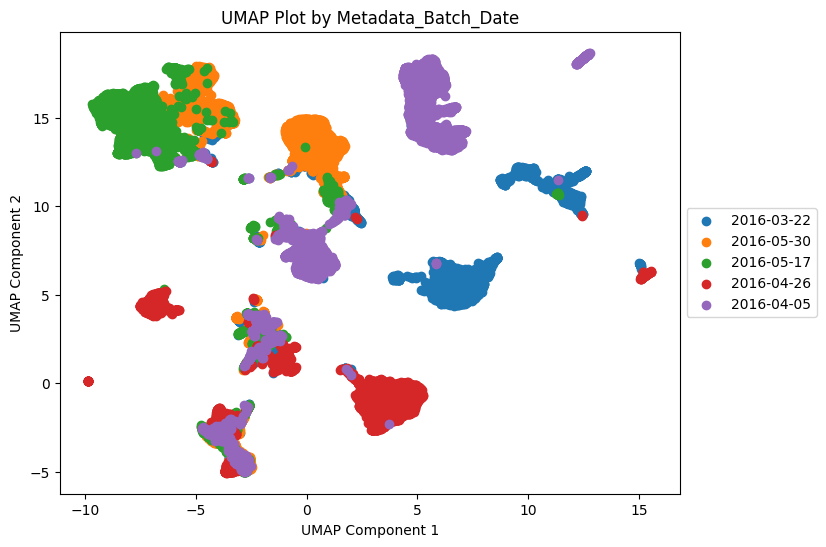

In [ ]:
num = 25
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
x_df = pd.DataFrame(Xs)
x_df['cell_line'] = X[X.columns[25]]
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

In [ ]:
X_train, X_test = train_test_split(X_tsne_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9791038345540716, test score = 0.973767352800383


In [ ]:
X_train, X_test = train_test_split(X_tsne_30, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9778591603236153, test score = 0.9728099569171853


In [ ]:
X_train, X_test = train_test_split(X_tsne_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9775240557231079, test score = 0.9722355193872666


In [ ]:
X_train, X_test = train_test_split(X_pca, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.6876585762841687, test score = 0.6298707515557683


In [ ]:
X_train, X_test = train_test_split(X_umap_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9695294173967159, test score = 0.9599808520823361


In [ ]:
X_train, X_test = train_test_split(X_umap_30, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9650055052898655, test score = 0.9564384873145045


In [ ]:
X_train, X_test = train_test_split(X_umap_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9622767964000192, test score = 0.9542364767831498


In [ ]:
x_df = pd.DataFrame(X_samp)
x_df['cell_line'] = X_samp['Metadata_Batch_Date']
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

In [ ]:
X_train, X_test = train_test_split(holes_df, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.4163914021733927, test score = 0.25904652498564046


### March 22nd, 2016

In [ ]:
X = X[X['Metadata_Batch_Date']=='2016-03-22']
X

,Metadata_plate_map_name,Metadata_broad_sample,Metadata_mg_per_ml,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,Metadata_pert_mfc_id,Metadata_pert_well,Metadata_pert_id_vendor,Metadata_cell_id,...,moa,target,broad_date,clinical_phase,alternative_moa,alternative_target,Metadata_dose_recode,Metadata_pert_id_dose,pert_type,control_type
0,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A01,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
1,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A02,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
2,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A03,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
3,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A04,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
4,C-7161-01-LM6-018,DMSO,0.000000,0.000000,DMSO,NaN,NaN,A05,NaN,A549,...,NaN,NaN,NaN,NaN,NaN,NaN,0.04,negcon,control,negcon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50682,C-7161-01-LM6-015,BRD-K61567297-001-01-9,1.206100,3.333300,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P20,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,3.33,BRD-K61567297_3.33,trt,NaN
50683,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.402020,1.111100,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P21,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,1.11,BRD-K61567297_1.11,trt,NaN
50684,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.134010,0.370370,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P22,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,0.37,BRD-K61567297_0.37,trt,NaN
50685,C-7161-01-LM6-015,BRD-K61567297-001-01-9,0.044669,0.123460,DMSO,BRD-K61567297,BRD-K61567297-001-01-9,P23,NaN,A549,...,toll-like receptor inhibitor,TLR4,broad_id_20170327,Phase 3,NaN,NaN,0.12,BRD-K61567297_0.12,trt,NaN


In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X[X.columns[26:-17]])

In [ ]:
tsne = TSNE(n_components=2, random_state=42, perplexity = 10)
X_tsne_10 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42)
X_tsne_30 = tsne.fit_transform(Xs)
tsne = TSNE(n_components=2, random_state=42, perplexity = 50)
X_tsne_50 = tsne.fit_transform(Xs)

In [ ]:
df = X_tsne

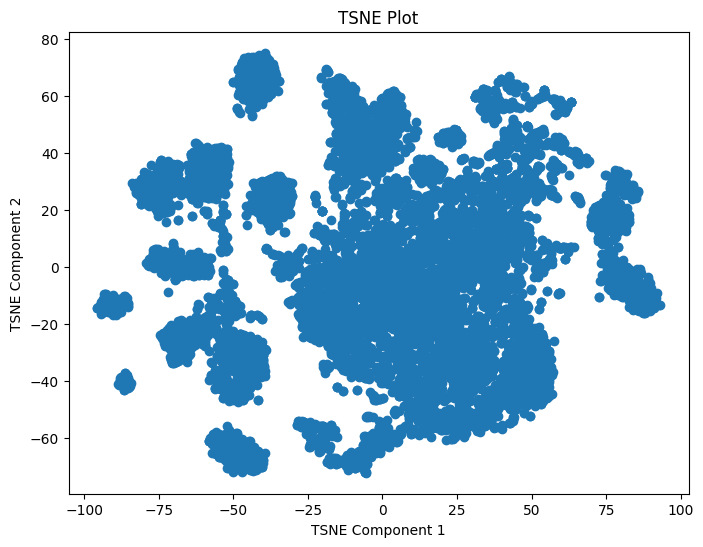

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(df[:,0], df[:,1], label = i)
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

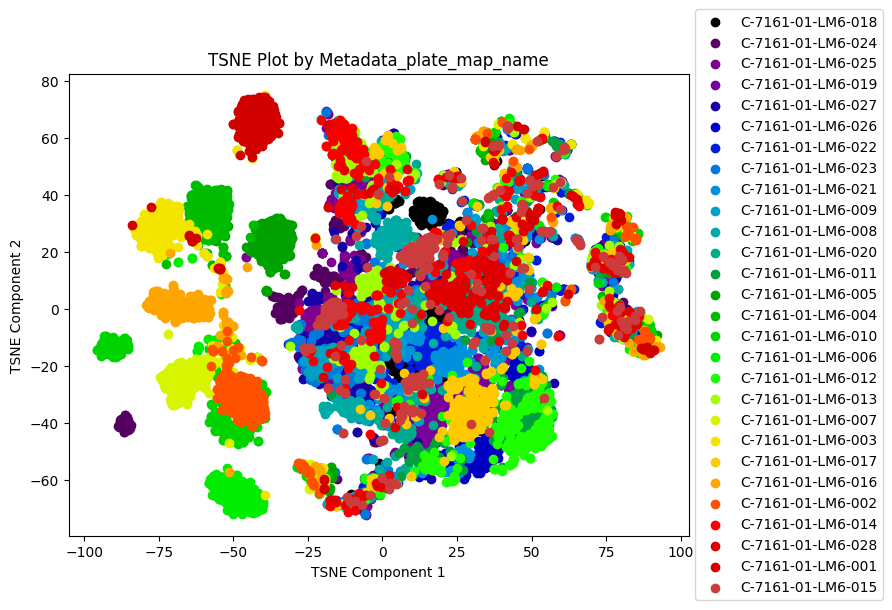

In [ ]:
num = 0
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by '+X.columns[num])
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 29))
plt.gca().set_prop_cycle('color',colors)
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

### Plate Normalization

In [ ]:
X = X.dropna(subset = ['Metadata_moa'])

In [ ]:
df_list = []
for i in X['Metadata_Plate'].unique():
  plate_df = X[X['Metadata_Plate']==i]
  ss = StandardScaler()
  Xs = ss.fit_transform(plate_df[plate_df.columns[26:-17]])
  df_list.append(pd.DataFrame(Xs))

In [ ]:
Xs = pd.concat(df_list)

In [ ]:
# tsne = TSNE(perplexity = 10)
# X_tsne_10 = tsne.fit_transform(Xs)
tsne = TSNE(perplexity = 30)
X_tsne_30 = tsne.fit_transform(Xs)
# tsne = TSNE(perplexity = 50)
# X_tsne_50 = tsne.fit_transform(Xs)
# pca = PCA(n_components=2)
# X_pca = pca.fit_transform(Xs)
# umap = UMAP(n_components=2, n_neighbors = 10)
# X_umap_10 = umap.fit_transform(Xs)
# umap = UMAP(n_components=2, n_neighbors = 30)
# X_umap_30 = umap.fit_transform(Xs)
# umap = UMAP(n_components=2, n_neighbors = 50)
# X_umap_50 = umap.fit_transform(Xs)

In [ ]:
X_train, X_test = train_test_split(Xs, test_size=0.2, random_state=42)

In [ ]:
df = X_tsne_10

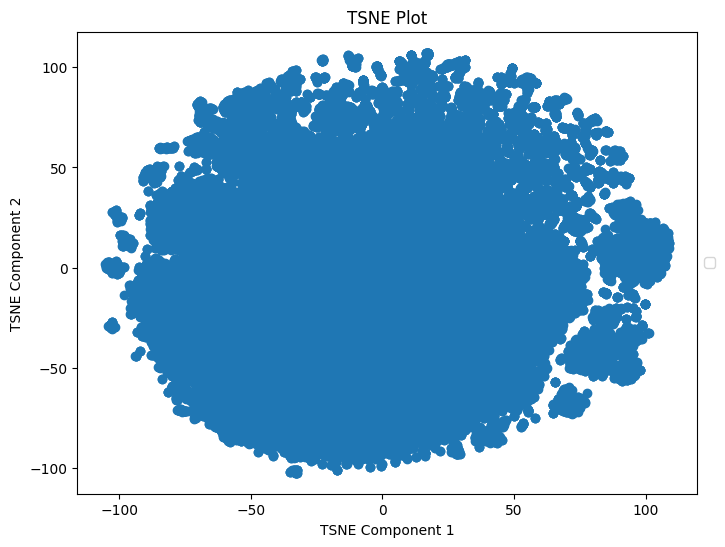

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_30

<ipython-input-16-616cb8d7162e>:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))


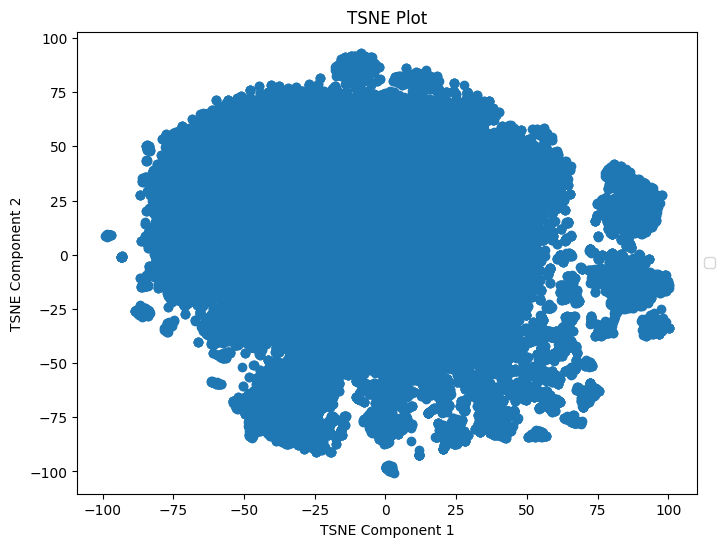

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

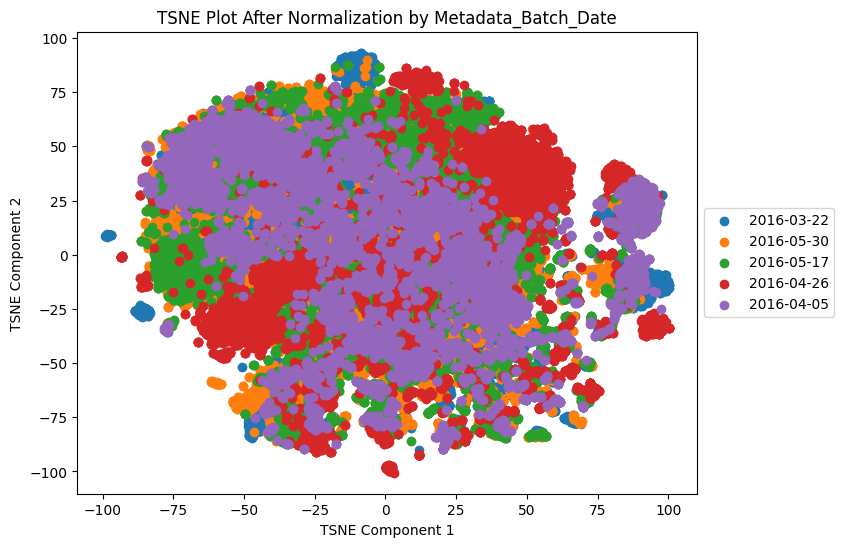

In [ ]:
num=25
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot After Normalization by '+X.columns[num])
for i in X[X.columns[num]].unique():
  plt.scatter(df[X[X.columns[num]]==i,0], df[X[X.columns[num]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_50

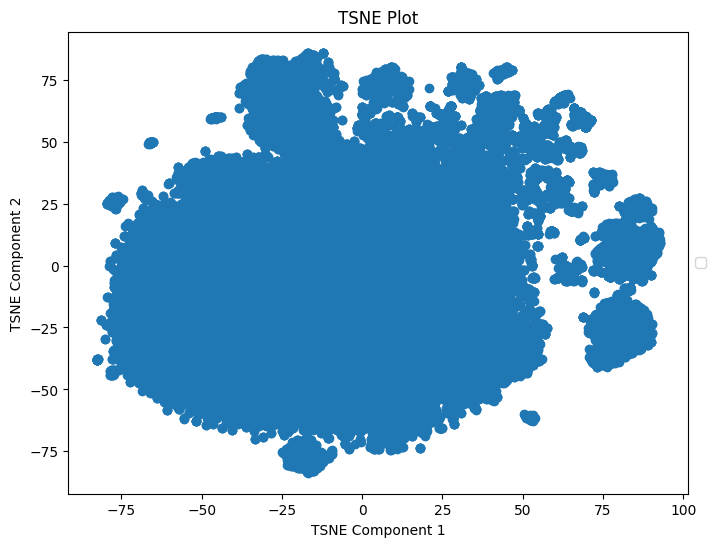

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_umap_10

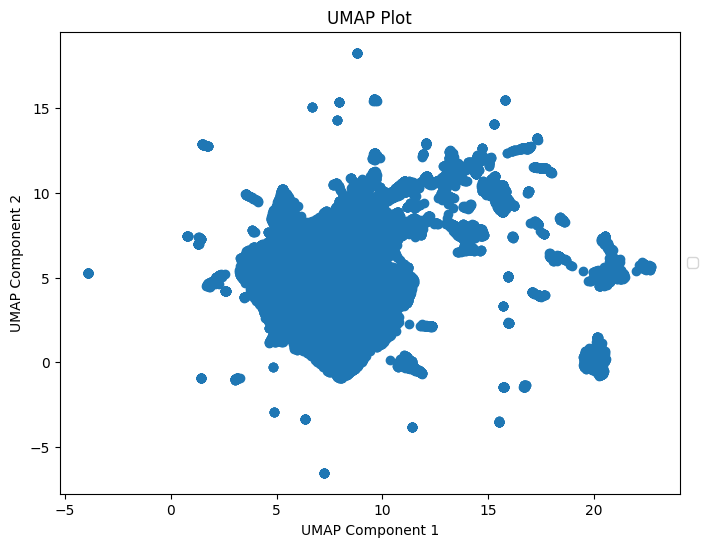

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_30

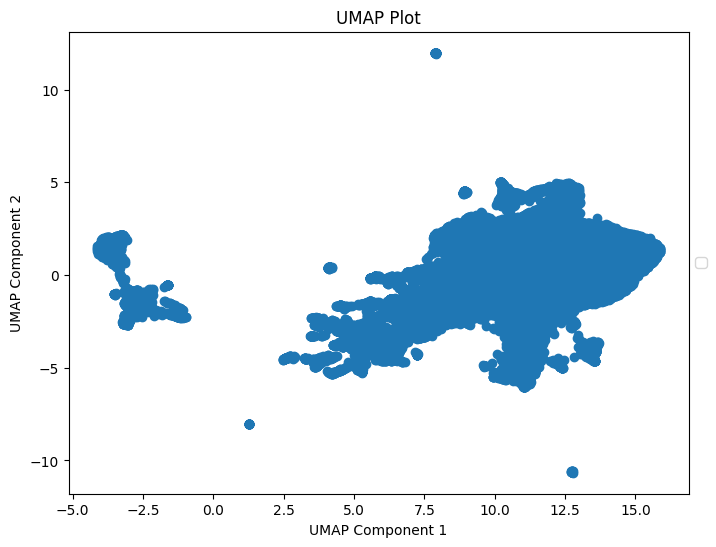

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_50

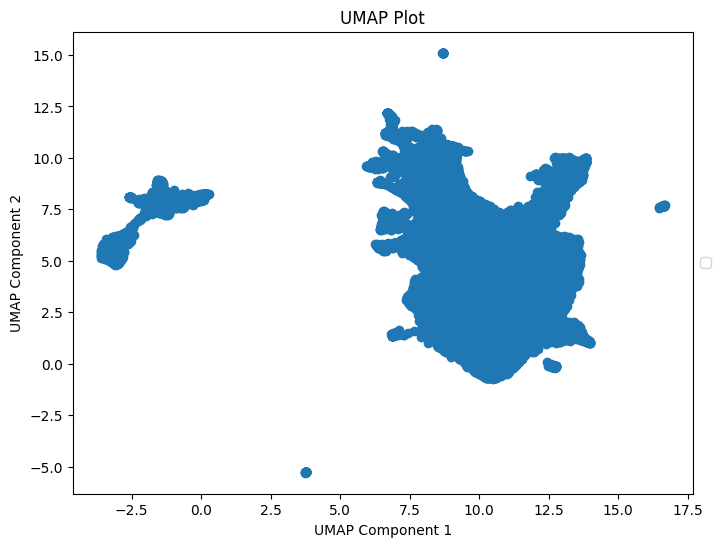

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot')
plt.scatter(df[:,0], df[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_pca

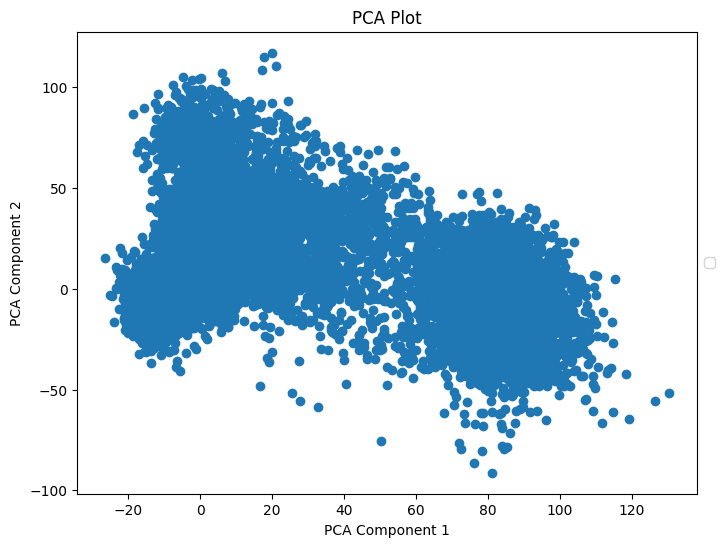

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot')
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

<ipython-input-24-c8a3eea731e3>:20: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


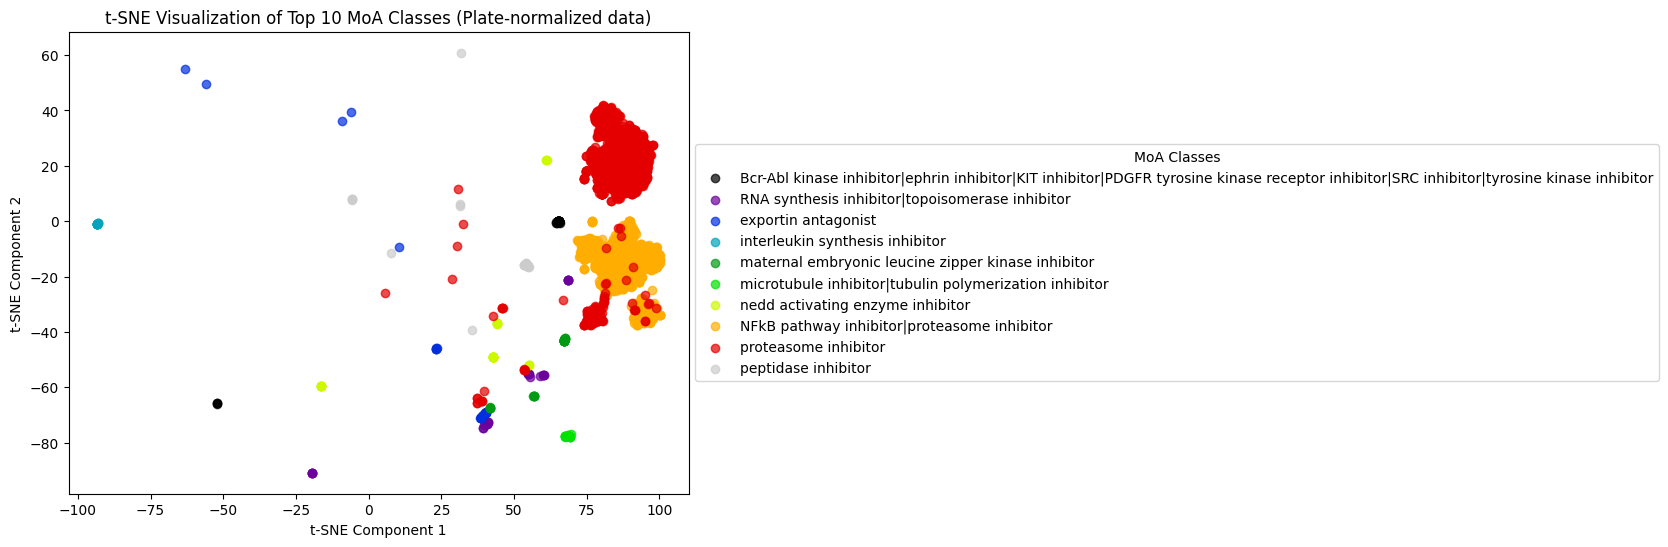

In [ ]:
# Extract top 10 MoA classes based on F1 scores
top_moas = [item[0] for item in sorted_f1_scores[:10]]

# Prepare color map
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, len(top_moas)))
plt.figure(figsize=(8, 6))
plt.gca().set_prop_cycle('color', colors)

plt.title('t-SNE Visualization of Top 10 MoA Classes (Plate-normalized data)')

# Plot each MoA separately
for moa in top_moas:
    mask = (X['Metadata_moa'] == moa).values
    plt.scatter(df[mask, 0], df[mask, 1], label=moa, alpha=0.7)

plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="MoA Classes")
plt.tight_layout()
plt.show()

In [ ]:
df = X_tsne_10

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.4683131039203812, test score = 0.25726621735467564


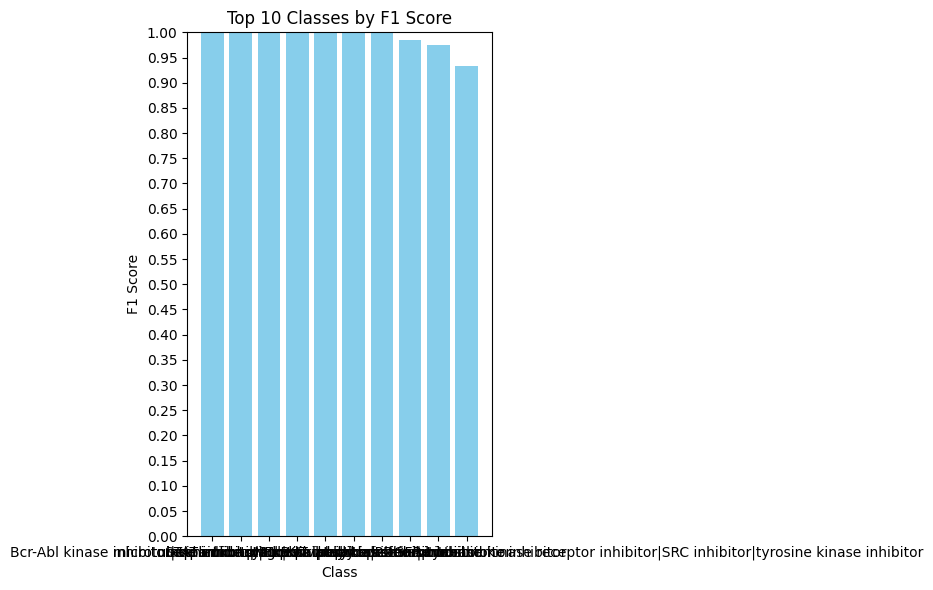

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['STAT inhibitor',
 'exportin antagonist',
 'interleukin synthesis inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'niacinamide phosphoribosyltransferase inhibitor',
 'p21 activated kinase inhibitor',
 'peptidase inhibitor',
 'NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'Bcr-Abl kinase inhibitor|ephrin inhibitor|KIT inhibitor|PDGFR tyrosine kinase receptor inhibitor|SRC inhibitor|tyrosine kinase inhibitor']

In [ ]:
df = X_tsne_30

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.4580711408335747, test score = 0.25073715248525696


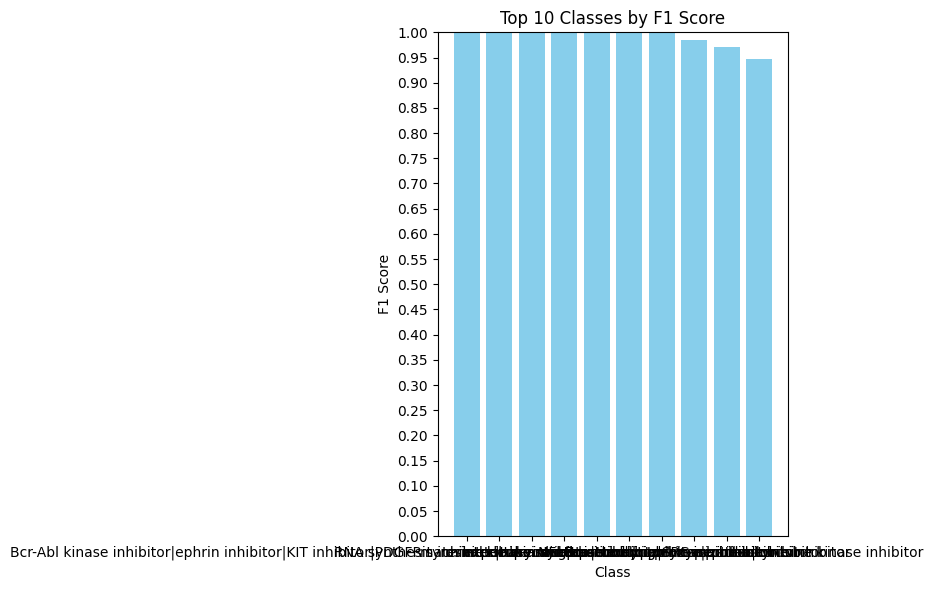

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['Bcr-Abl kinase inhibitor|ephrin inhibitor|KIT inhibitor|PDGFR tyrosine kinase receptor inhibitor|SRC inhibitor|tyrosine kinase inhibitor',
 'RNA synthesis inhibitor|topoisomerase inhibitor',
 'exportin antagonist',
 'interleukin synthesis inhibitor',
 'maternal embryonic leucine zipper kinase inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'peptidase inhibitor',
 'NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'niacinamide phosphoribosyltransferase inhibitor']

In [ ]:
df = X_tsne_50

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.4512256128064032, test score = 0.24505054759898906


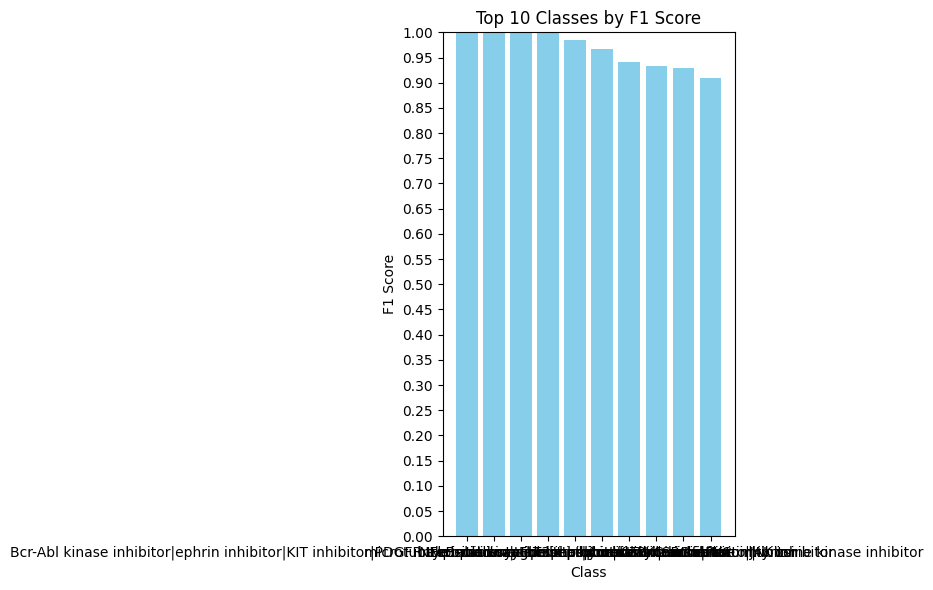

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['Bcr-Abl kinase inhibitor|ephrin inhibitor|KIT inhibitor|PDGFR tyrosine kinase receptor inhibitor|SRC inhibitor|tyrosine kinase inhibitor',
 'exportin antagonist',
 'interleukin synthesis inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'niacinamide phosphoribosyltransferase inhibitor',
 'FLT3 inhibitor|KIT inhibitor|PKC inhibitor',
 'PKC activator',
 'Aurora kinase inhibitor|JAK inhibitor']

In [ ]:
df = X_umap_10

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.3602327479529238, test score = 0.17607413647851727


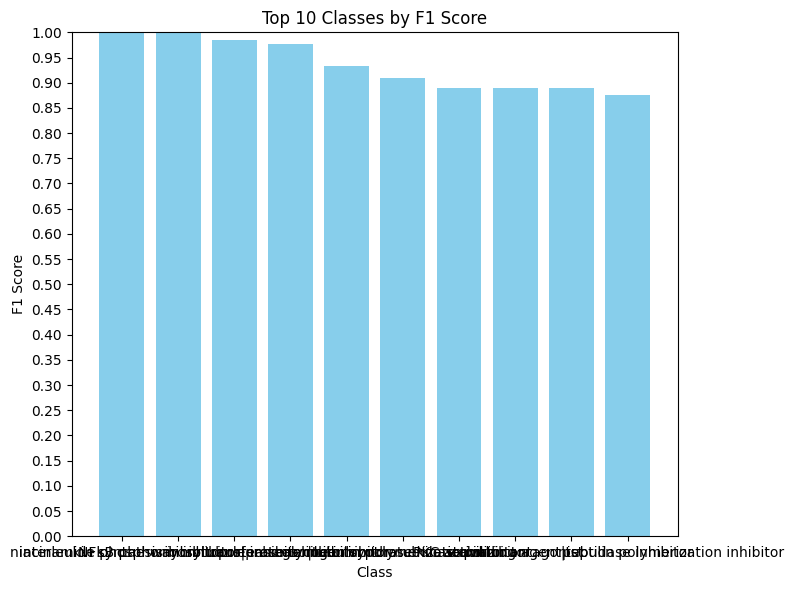

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
# plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['interleukin synthesis inhibitor',
 'niacinamide phosphoribosyltransferase inhibitor',
 'NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'glycogen synthase kinase inhibitor',
 'PKC activator',
 'exportin antagonist',
 'microtubule stabilizing agent|tubulin polymerization inhibitor',
 'peptidase inhibitor']

In [ ]:
df = X_umap_30

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.3409862826149917, test score = 0.15490732940185342


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


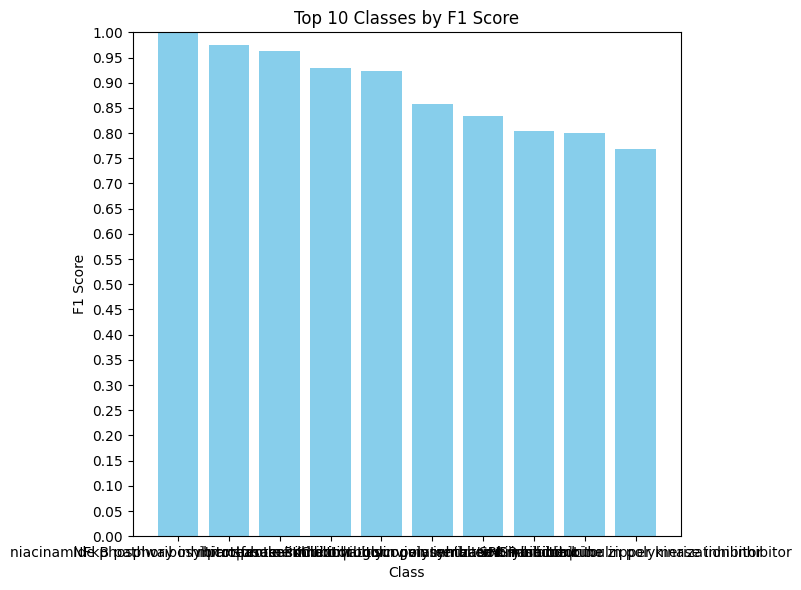

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
# plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['niacinamide phosphoribosyltransferase inhibitor',
 'NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'PKC activator',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'survivin inhibitor',
 'glycogen synthase kinase inhibitor',
 'HSP inhibitor',
 'maternal embryonic leucine zipper kinase inhibitor',
 'SRC inhibitor|tubulin polymerization inhibitor']

In [ ]:
df = X_umap_50

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.3327716489823859, test score = 0.14532434709351305


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


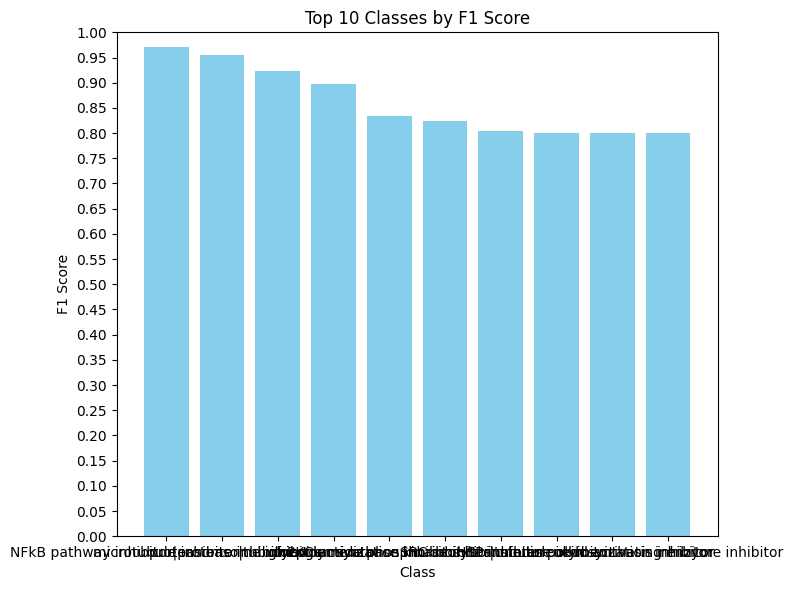

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
# plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'PKC activator',
 'glycogen synthase kinase inhibitor',
 'niacinamide phosphoribosyltransferase inhibitor',
 'HSP inhibitor',
 'SRC inhibitor|tubulin polymerization inhibitor',
 'interleukin synthesis inhibitor',
 'nedd activating enzyme inhibitor']

In [ ]:
df = X_pca

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=5
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.27745451673205024, test score = 0.08034962089300758


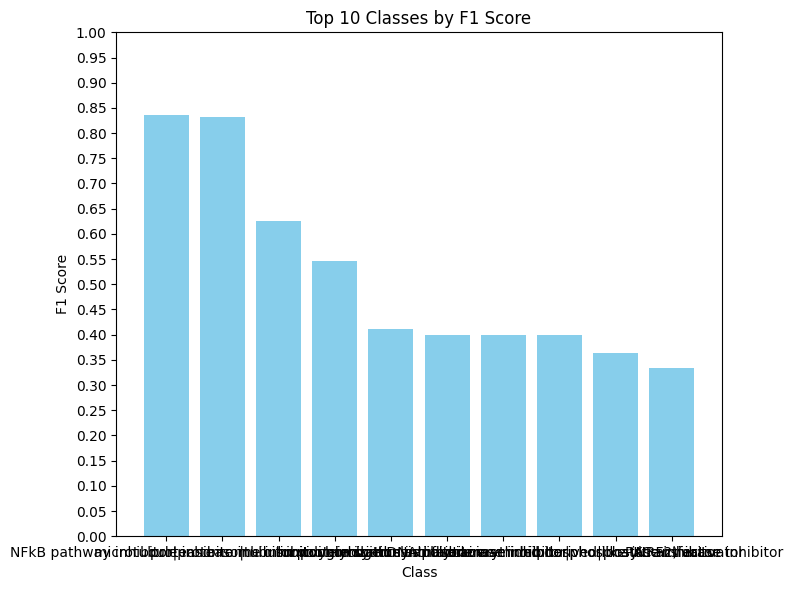

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(8, 6))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
# plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
# plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
classes

['NFkB pathway inhibitor|proteasome inhibitor',
 'proteasome inhibitor',
 'microtubule inhibitor|tubulin polymerization inhibitor',
 'survivin inhibitor',
 'protein synthesis inhibitor',
 'glycogen synthase kinase inhibitor',
 'mitochondrial DNA polymerase inhibitor|phosphatase inhibitor',
 'nuclear factor erythroid derived|like (NRF2) activator',
 'niacinamide phosphoribosyltransferase inhibitor',
 'PKC activator']